In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
from torch.utils.data import DataLoader

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
# You can use any of the 4 train files or all the files for pre-training the legal model



# Training configuration
TARGET_TOKENS = 500_000_000
MAX_SEQ_LEN = 1024  #CONTEXT LENGTH
TRAIN_STEPS = 1
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 512
N_LAYER = 8
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95
VOCAB_SIZE = 8000
MODEL_DIM = 512
MODEL_LAYERS = 12
MODEL_FF = 4096
N_HEADS = 8
N_KV_HEADS = 8
BATCH_SIZE = 16
# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase2"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

cuda
Configuration loaded.


In [4]:
from huggingface_hub import hf_hub_download

TRAIN_FILES = [
    "Phase_3_RR/Train/CL_train.json",
    "Phase_3_RR/Train/IT_train.json",
]

train_file_paths = {}

for filename in TRAIN_FILES:
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        token=HF_TOKEN
    )

    train_file_paths[filename] = path
    print(f"{filename}")
    print(f"  {path}")

CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Phase_3_RR/Train/CL_train.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Train/CL_train.json


IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

Phase_3_RR/Train/IT_train.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Train/IT_train.json


In [5]:
from huggingface_hub import hf_hub_download

VAL_FILES = [
    "Phase_3_RR/Train/CL_dev.json",
    "Phase_3_RR/Train/IT_dev.json",
]

val_file_paths = {}

for filename in VAL_FILES:
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        token=HF_TOKEN
    )

    val_file_paths[filename] = path
    print(f"{filename}")
    print(f"  {path}")

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

Phase_3_RR/Train/CL_dev.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Train/CL_dev.json


IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

Phase_3_RR/Train/IT_dev.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Train/IT_dev.json


In [6]:
from huggingface_hub import hf_hub_download

TEST_FILES = [
    "Phase_3_RR/Test/CL_test.json",
    "Phase_3_RR/Test/IT_test.json",
]

test_file_paths = {}

for filename in TEST_FILES:
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        token=HF_TOKEN
    )

    test_file_paths[filename] = path
    print(f"{filename}")
    print(f"  {path}")

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

Phase_3_RR/Test/CL_test.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Test/CL_test.json


IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Phase_3_RR/Test/IT_test.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Test/IT_test.json


In [7]:
from huggingface_hub import hf_hub_download

LABEL_FILE = ["Phase_3_RR/Train/label_vocab.json"]

label_file_paths = {}

for filename in LABEL_FILE:
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        token=HF_TOKEN
    )

    label_file_paths[filename] = path
    print(f"{filename}")
    print(f"  {path}")

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Phase_3_RR/Train/label_vocab.json
  /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_3_RR/Train/label_vocab.json


In [8]:
import json
import pandas as pd

with open(train_file_paths["Phase_3_RR/Train/CL_train.json"], "r") as f:
    cl_train_data = json.load(f)
with open(train_file_paths["Phase_3_RR/Train/IT_train.json"], "r") as f:
    it_train_data = json.load(f)
    
with open(val_file_paths["Phase_3_RR/Train/CL_dev.json"], "r") as f:
    cl_val_data = json.load(f)
with open(val_file_paths["Phase_3_RR/Train/IT_dev.json"], "r") as f:
    it_val_data = json.load(f)
    

    
with open(label_file_paths["Phase_3_RR/Train/label_vocab.json"], "r") as f:
    labels_data = json.load(f)

print(type(labels_data))


<class 'dict'>


In [9]:
with open(test_file_paths["Phase_3_RR/Test/CL_test.json"], "r") as f:
    cl_test_data = json.load(f)
with open(test_file_paths["Phase_3_RR/Test/IT_test.json"], "r") as f:
    it_test_data = json.load(f)

In [10]:
labels_data

{'Fact': 0,
 'Issue': 1,
 'ArgumentPetitioner': 2,
 'ArgumentRespondent': 3,
 'Statute': 4,
 'Dissent': 5,
 'PrecedentReliedUpon': 6,
 'PrecedentNotReliedUpon': 7,
 'PrecedentOverruled': 8,
 'RulingByLowerCourt': 9,
 'RatioOfTheDecision': 10,
 'RulingByPresentCourt': 11,
 'None': 12}

In [11]:

class Node:
    def __init__(self,value, previous, next, index):
        self.value=value
        self.previous=previous
        self.next=next
        self.index=index


class LinkedArray:
    def __init__(self, items):
        self._array=[None for _ in range(len(items))]
        previous=None
        for i in range(len(items)):
            node=Node(items[i], previous, None, i)
            if previous is not None:
                node.previous=previous
                previous.next=node
            self._array[i]=node
            previous=node

    def get_previous_index(self, index):
        if self._array[index]==None:
            raise ValueError(f"No item at index {index}")
        if self._array[index].previous == None:
            return None
        return self._array[index].previous.index

    def get_next_index(self, index):
        if self._array[index]==None:
            raise ValueError(f"No item at index {index}")
        if self._array[index].next == None:
            return None
        return self._array[index].next.index

    def get_by_index(self, index):
        if self._array[index]==None:
            raise ValueError(f"No item at index {index}")
        if self._array[index] == None:
            return None
        return self._array[index].value

    def get_second_next_index(self, index):
        if self._array[index] == None:
            raise ValueError(f"No item at index {index}")
        if self._array[index].next == None or self._array[index].next.next == None:
            return None
        return self._array[index].next.next.index

    def len(self):
        return len(self._array)
    def exists(self, index):
        return (
            0 <= index < len(self._array)
            and self._array[index] is not None
        )

    def replace_pair(self, index, new_item):
        if index > len(self._array)-2 or self._array[index] == None or self._array[index].next == None:
            raise ValueError("Invalid index ",index,new_item)
        self._array[index].value = new_item
        self._array[self._array[index].next.index] = None
        self._array[index].next = self._array[index].next.next
        if self._array[index].next is not None:
            self._array[index].next.previous = self._array[index]


class MaxPriorityMap:
    def __init__(self, heap_key, map_key):
        self._heap_key = heap_key
        self._map_key = map_key
        self._heap = []
        # Map of keys to indexes in the heap
        self._map = {}

    def get_max(self):
        if len(self._heap) == 0:
            raise ValueError("the heap is empty")
        return self._heap[0]

    def push(self, item):
        self._heap.append(item)
        map_key = self._map_key(item)
        if map_key in self._map:
            raise ValueError("Map key already exist")
        self._map[self._map_key(item)] = len(self._heap) - 1
        self._heapify_up(len(self._heap) - 1)

    def pop(self):
        if len(self._heap) == 0:
            raise ValueError("the heap is empty")
        self._swap(0, len(self._heap) - 1)
        item = self._heap.pop()
        map_key = self._map_key(item)
        self._map.pop(map_key)
        self._heapify_down(0)
        return item

    def contains(self, map_key):
        return map_key in self._map

    def len(self):
        if len(self._heap) != len(self._map):
            raise ValueError('Invalid state of the priority map')
        return len(self._heap)

    def delete_by_map_key(self, map_key):
        if map_key not in self._map:
            raise ValueError("Map key does not exist")
        heap_index = self._map[map_key]
        item = self._heap[heap_index]
        self._swap(heap_index, len(self._heap) - 1)
        self._heap.pop()
        self._map.pop(map_key)
        if (heap_index < len(self._heap)):
            self._heapify_down(heap_index)
            self._heapify_up(heap_index)
        return item

    def _heapify_up(self, i):
        while i > 0 and self._heap_key(self._heap[i]) > self._heap_key(self._heap[self._parent(i)]):
            self._swap(i, self._parent(i))
            i = self._parent(i)

    def _heapify_down(self, i):
        largest = i
        left = self._left_child(i)
        right = self._right_child(i)

        if left < len(self._heap) and self._heap_key(self._heap[left]) > self._heap_key(self._heap[largest]):
            largest = left

        if right < len(self._heap) and self._heap_key(self._heap[right]) > self._heap_key(self._heap[largest]):
            largest = right

        if largest != i:
            self._swap(i, largest)
            self._heapify_down(largest)

    def _parent(self, i):
        return (i - 1) // 2

    def _left_child(self, i):
        return 2 * i + 1

    def _right_child(self, i):
        return 2 * i + 2

    def _swap(self, i, j):
        self._map[self._map_key(self._heap[i])] = j
        self._map[self._map_key(self._heap[j])] = i
        self._heap[i], self._heap[j] = self._heap[j], self._heap[i]


class StatsEntry:
    def __init__(self, pair, positions):
        self.pair = pair
        self.positions = positions

class TokenizerTrainer:
        def __init__(self, tokens_list, itos, num_merges):
            self.tokens_list = tokens_list
            self.itos = itos
            self._num_merges = num_merges
            self.stoi={}

        def train(self, next_token):
            self._positions=[LinkedArray(tokens) for tokens in self.tokens_list]
            self.get_stats()
            merges_done=0
            print("requested merges",self._num_merges)
            while  merges_done<self._num_merges:
                if self._stats.len() == 0:
                   print("STOPPED: stats became empty")
                   print("Merges completed:", merges_done)
                   break
                merge_stat = self._stats.pop()
                (current_token , next_token) = self.update_itos_and_stoi(next_token, merge_stat)
                #iterate through posistions replace with merge pair
                for position in list(merge_stat.positions):

                    if position not in merge_stat.positions:
                        continue
                    input_index = position[0]
                    token_index = position[1]
                    # print("current_token",current_token)
                    if not self._positions[input_index].exists(token_index):
                        merge_stat.positions.discard(position)
                        continue
                    self.update_right_token(input_index, token_index, merge_stat, current_token)
                    self.update_left_token(input_index, token_index, merge_stat, current_token)
                    self._positions[input_index].replace_pair(token_index, current_token)
                    merge_stat.positions.remove((input_index, token_index))
                merges_done += 1
            return self.itos


        def update_right_token(self, input_index, token_index, merge_stat, current_token):
           position = self._positions[input_index]
           next_token_idx = position.get_next_index(token_index)
           right_token_idx = position.get_second_next_index(token_index)
           if right_token_idx == None:
               return
           pair = (merge_stat.pair[1], position.get_by_index(right_token_idx))
           self.remove_pair_from_stats(merge_stat, pair, input_index, next_token_idx)
           new_pair = (current_token, pair[1])
           self.add_position_to_pair(new_pair, input_index, token_index)

        def update_left_token(self, input_index, token_index, merge_stat, current_token):
           position = self._positions[input_index]
           left_token_idx = position.get_previous_index(token_index)
           if left_token_idx == None:
               return
           pair = ( position.get_by_index(left_token_idx), merge_stat.pair[0])
           self.remove_pair_from_stats(merge_stat, pair, input_index, left_token_idx)
           new_pair = (pair[0] , current_token)
           self.add_position_to_pair(new_pair, input_index, left_token_idx)

        def add_position_to_pair(self, new_pair, input_index, token_index):
            if self._stats.contains(new_pair):
                stat = self._stats.delete_by_map_key(new_pair)
            else:
                stat = StatsEntry(new_pair, set())

            stat.positions.add((input_index, token_index))
            self._stats.push(stat)


        def remove_pair_from_stats(self, merge_stat, pair, input_index, token_index):
           if pair == merge_stat.pair:
               merge_stat.positions.discard((input_index, token_index))
           else:
                if self._stats.contains(pair):
                    stat = self._stats.delete_by_map_key(pair)
                    stat.positions.discard((input_index, token_index))
                    if len(stat.positions) != 0:
                        self._stats.push(stat)


        def update_itos_and_stoi(self, next_token, merge_stat):
           merge_pair = self.itos[merge_stat.pair[0]] + self.itos[merge_stat.pair[1]]
           if merge_pair in self.stoi:
               current_token = self.stoi[merge_pair]
           else:
               current_token = next_token
               self.itos[current_token] = merge_pair
               self.stoi[merge_pair] = current_token
               next_token = current_token+1
           return  (current_token , next_token)

        def get_stats(self):
             self._stats = MaxPriorityMap(
                                heap_key=lambda item: (len(item.positions),tuple(-x for x in item.pair)),
                                map_key=lambda item: item.pair
                            )
             stats={}
             for  text_id in range(len(self.tokens_list)):
                 tokens = self.tokens_list[text_id]
                 for idx in range(len(tokens)-1):
                     pair = (tokens[idx], tokens[idx+1])
                     if pair not in stats:
                         stats[pair]=StatsEntry(pair, set())
                     stats[pair].positions.add((text_id, idx))
             for key in stats.keys():
                self._stats.push(stats[key])

class TokenNode:
    def __init__(self, byte_value, token, parent, children):
        self.parent = parent
        self.byte_value = byte_value
        self.token = token
        self.children = children

class ToTokensConverter:

    def __init__(self, itos):
        self.itos = itos
        self.unk_token=1
        self._init_token_tree()

    def to_tokens(self, strings):
        return [
            self._to_tokens(string)
            for string in strings
        ]

    def _to_tokens(self, string):

        words = string.split()
        tokens = []
        for word in words:
            data = word.encode("utf-8") + b"</w>"
            word_tokens = self._tokenize_word(data)
            tokens.extend(word_tokens)
        return tokens

    def _tokenize_word(self, data):

        tokens = []

        byte_index = 0

        while byte_index < len(data):

            current_nodes = self._token_roots

            last_node_with_token = None
            last_index_with_token = byte_index

            while byte_index < len(data):

                byte_value = data[byte_index]

                if byte_value in current_nodes:

                    node = current_nodes[byte_value]

                    if node.token is not None:
                        last_node_with_token = node
                        last_index_with_token = byte_index

                    current_nodes = node.children
                    byte_index += 1

                else:
                    break

            if last_node_with_token is None:
                tokens.append(self.unk_token)

                # Move forward by one byte
                byte_index += 1

            else:
                tokens.append(last_node_with_token.token)
                byte_index = last_index_with_token + 1

        return tokens

    def _init_token_tree(self):

        self._token_roots = {}

        for token, token_bytes in self.itos.items():

            if token < 4:
                continue

            current_nodes = self._token_roots
            last_node = None

            for byte_value in token_bytes:

                if byte_value in current_nodes:

                    last_node = current_nodes[byte_value]

                else:

                    last_node = TokenNode(
                        byte_value,
                        None,
                        last_node,
                        {}
                    )

                    current_nodes[byte_value] = last_node

                current_nodes = last_node.children

            if last_node.token is not None:
                raise KeyError("The token is already taken")

            last_node.token = token

class BPETokenizer:
    def __init__(self, num_merges):
        self._num_merges = num_merges
        self.itos = {}
    def get_vocab_size(self):
        return len(self.itos)
    def train(self, texts):
        self.create_base_vocab()

        tokens_list = self.get_ids_from_text(texts)
        # for tokens in tokens_list:
        #     print(tokens)
        trainer = TokenizerTrainer(
                        tokens_list,
                        self.itos,
                        self._num_merges
                    )

        trainer.train(261)

        return self.itos, tokens_list

    def encode(self, text):
        converter = ToTokensConverter(self.itos)
        return converter.to_tokens([text])[0]

    def decode(self, tokens):
        return (
                b"".join(
                    self.itos[token]
                    for token in tokens
                )
                .decode("utf-8", errors="replace")
                .replace("</w>", " ")
                .strip()
            )

    def create_base_vocab(self):
        self.itos = {
            0: b"<pad>",
            1: b"<unk>",
            2: b"<s>",
            3: b"</s>",
            260 : b"</w>"
        }
        for i in range(256):
            self.itos[i + 4] = bytes([i])

    def get_ids_from_text(self, texts):
        tokens_list=[]
        for text in texts:
            words = text.split()
            for word in words:
                word_bytes = [byte + 4 for byte in word.encode("utf-8")]
                word_bytes.append(260)
                tokens_list.append(word_bytes)
        return tokens_list

In [12]:
import numpy as np
import pickle

# Paths
bpe_path = "/kaggle/input/datasets/saiveerendra2151/tokenizer-results/project_bpe_16k.pkl"

# Load BPE tokenizer
with open(bpe_path, "rb") as f:
    tokenizer = pickle.load(f)
print("BPE vocab size:", len(tokenizer.itos))


BPE vocab size: 7999


In [13]:
converter = ToTokensConverter(tokenizer.itos)

In [14]:
def get_token_lengths(data, tokenizer):
    lengths = []

    for record in data:
        for sentence in record["text"]:
            token_ids = converter.to_tokens([sentence])[0]
            lengths.append(len(token_ids))

    return lengths


cl_lengths = get_token_lengths(cl_train_data, tokenizer)
it_lengths = get_token_lengths(it_train_data, tokenizer)

import numpy as np

for name, lengths in [("CL", cl_lengths), ("IT", it_lengths)]:
    print(f"\n{name}")
    print("Max:", max(lengths))
    print("P95:", np.percentile(lengths, 95))
    print("P99:", np.percentile(lengths, 99))
    print("Over 512:", sum(x > 512 for x in lengths))
    print("Over 1024:", sum(x > 1024 for x in lengths))


CL
Max: 992
P95: 97.0
P99: 159.0
Over 512: 4
Over 1024: 0

IT
Max: 1326
P95: 108.0
P99: 197.0
Over 512: 3
Over 1024: 1


In [15]:
def get_token_lengths_test(data, tokenizer):
    lengths = []

    for doc_id,sentences in data.items():
        for sentence in sentences:
            token_ids = converter.to_tokens([sentence])[0]
            lengths.append(len(token_ids))

    return lengths


cl_lengths = get_token_lengths_test(cl_test_data, tokenizer)
it_lengths = get_token_lengths_test(it_test_data, tokenizer)

import numpy as np

for name, lengths in [("CL", cl_lengths), ("IT", it_lengths)]:
    print(f"\n{name}")
    print("Max:", max(lengths))
    print("P95:", np.percentile(lengths, 95))
    print("P99:", np.percentile(lengths, 99))
    print("Over 512:", sum(x > 512 for x in lengths))
    print("Over 1024:", sum(x > 1024 for x in lengths))


CL
Max: 686
P95: 99.0
P99: 172.33999999999924
Over 512: 1
Over 1024: 0

IT
Max: 368
P95: 113.0
P99: 207.8599999999999
Over 512: 0
Over 1024: 0


In [16]:

"""Rotary Positional Embeddings, implemented from scratch."""
import torch


def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """
    Returns (cos, sin) tensors of shape (max_seq_len, d_head) ready to be applied to
    query/key tensors of head dimension d_head. d_head must be even. This scaffold uses
    the split-half rotate_half convention: channel i is paired with channel i+d_head/2.
    """
    assert d_head % 2 == 0, "RoPE requires an even head dimension"
    inverse_frequencies =torch.tensor([1/base ** (2*i/d_head) for i in range(d_head//2)],dtype = torch.float32)
    positions = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(positions, inverse_frequencies)
    angles = torch.cat([freqs, freqs], dim=-1)
    return angles.cos(), angles.sin()



def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Split the last dim in half and return (-x2, x1) concatenated -- the 90-degree
    rotation step used by the "rotate_half" formulation of RoPE."""
    # TODO
    d_head = x.shape[-1]
    x1, x2 = x[...,:d_head//2], x[...,d_head//2:]
    return torch.cat([-x2, x1], dim=-1)



def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """
    x: (B, n_heads, T, d_head) -- a query or key tensor.
    cos, sin: (T, d_head), sliced from build_rope_cache's output for the current T.
    Returns the rotated tensor, same shape as x.
    Formula: x_rotated = x * cos + rotate_half(x) * sin
    """
    # TODO: broadcast cos/sin to (1, 1, T, d_head) and apply the formula above
    cos = cos[None, None, :, :]
    sin = sin[None, None, :, :]
    x_rotated = x*cos + rotate_half(x)*sin
    return x_rotated



In [17]:

"""Attention supporting MHA/MQA/GQA (Q2) with a choice of positional scheme: RoPE applied
to q/k inside attention, or none (if positions are handled by sinusoidal PE at the input,
as in Q1)."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F



class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, dropout=0.0, use_rope=False, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.n_rep = n_heads // n_kv_heads
        self.d_head = d_model // n_heads
        self.use_rope = use_rope
        # Preserve the Q1.4 hook. None -> standard 1/sqrt(d_head).
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

        if use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x, padding_mask = None, past_kv=None, use_cache=False,  position_offset=0):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)

        if self.use_rope:
            # TODO: apply_rope to q and k (NOT v) using self.rope_cos[:T], self.rope_sin[:T]
            cos = self.rope_cos[ position_offset:position_offset + T]
            sin = self.rope_sin[position_offset:position_offset + T]
            q = apply_rope(q, cos, sin)
            k = apply_rope(k, cos, sin)
            
        if past_kv is not None:
            past_k, past_v = past_kv
            k = torch.cat([past_k, k],dim=2)
            v = torch.cat([past_v, v],dim=2)
        new_kv = (k, v) if use_cache else None

  

        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)

        # TODO: same attention as before, but compute scores as
        #       (q @ k.transpose(-2, -1)) * self.attention_scale before masking/softmax
        attn_scores = q @ k.transpose(-2, -1) * self.attention_scale
        
        T_q = q.size(2)
        T_k = k.size(2)
        if past_kv is None:

            mask = self.causal_mask[:T_q, :T_k]

            attn_scores = attn_scores.masked_fill(
                ~mask,
                float("-inf")
            )
        if padding_mask is not None:
        
            attn_scores = attn_scores.masked_fill(
                padding_mask[:, None, None, :],
                float("-inf")
            )
        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_weights = self.attn_dropout(attn_weights)
        out = attn_weights @ v
        out = out.transpose(1, 2).reshape(B, T, C)
        out = self.out_proj(out)
        out = self.resid_dropout(out)
        return out, new_kv


In [18]:

"""Decoder-only Transformer LM -- Block now passes use_rope through to attention, and
DecoderLM only builds/adds the sinusoidal table when pos_emb_type == "sinusoidal"
(everything else unchanged from Question 2)."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F



@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"   # "sinusoidal" or "rope"
    attention_scale: float = None      # preserve Q1.4 hook
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    PE = torch.zeros(max_len, d_model)
    for pos in range(max_len):
      for i in range(d_model//2):
        PE[pos, 2*i] = math.sin(pos / 10000**(2*i/d_model))
        PE[pos, 2*i+1] = math.cos(pos / 10000**(2*i/d_model))
    return PE



class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )   # unchanged from Question 1

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        # TODO: pass use_rope=(cfg.pos_emb_type == "rope") to CausalSelfAttention
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
                                        cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"),
                                        attention_scale=cfg.attention_scale)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x,  padding_mask = None, past_kv=None, use_cache=False,  position_offset=0):
        attn_out, new_kv = self.attn(
                self.ln1(x),
                padding_mask = padding_mask,
                past_kv=past_kv,
                use_cache=use_cache,
                position_offset=position_offset
            )

        x = x + attn_out
    
        x = x + self.ffn(
            self.ln2(x)
        )
    
        return x, new_kv   # unchanged from Question 1


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)
        # NOTE: when cfg.pos_emb_type == "rope", we deliberately do NOT build a
        # sinusoidal table at all -- position information is injected inside every
        # attention layer instead of once at the input.
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor, past_kvs=None, use_cache=False) -> torch.Tensor:
        B, T = idx.shape
        x =self.tok_emb(idx)
        if past_kvs is None:
            position_offset = 0
        else:
            position_offset = past_kvs[0][0].size(2)
        if self.cfg.pos_emb_type == "sinusoidal":
          x = x + self.pos_emb[position_offset:position_offset + T]
        new_kvs = [] if use_cache else None
        for i, block in enumerate(self.blocks):
          past_kv = (
                     None
                        if past_kvs is None
                        else past_kvs[i]
                    )
          x, new_kv = block(
            x,
            past_kv=past_kv,
            use_cache=use_cache,
            position_offset=position_offset
        )

          if use_cache:
                new_kvs.append(new_kv)
        
        logits = self.head(self.ln_f(x))
        if use_cache:
          return logits, new_kvs
        return logits # unchanged from Question 1 (just remember: only add
        # self.pos_emb when self.cfg.pos_emb_type == "sinusoidal")

In [19]:
class LoraLinear(nn.Module):
    def __init__(self, layer, rank=8, alpha=16, dropout=0.05):
        super().__init__()

        self.layer = layer
        self.rank = rank
        self.alpha = alpha
        self.dropout = nn.Dropout(dropout)

        # Freeze original layer
        for p in self.layer.parameters():
            p.requires_grad = False

        self.in_features = layer.in_features
        self.out_features = layer.out_features

        # A: [rank, in_features]
        self.A = nn.Parameter(
            torch.empty(rank, self.in_features)
        )

        # B: [out_features, rank]
        self.B = nn.Parameter(
            torch.zeros(self.out_features, rank)
        )

        nn.init.kaiming_uniform_(
            self.A,
            a=5**0.5
        )

    def forward(self, x):

        # Original path: W0 x
        W0x = self.layer(x)

        # LoRA path: BAx
        Ax = F.linear(self.dropout(x), self.A)
        BAx = F.linear( Ax, self.B)

        return W0x + (self.alpha / math.sqrt(self.rank)) * BAx

In [20]:
class LoraModel(nn.Module):
    def __init__(self, model, d_model, rank=8, alpha=16, dropout=0.05,
                 labels=25, projections=("q_proj", "v_proj")):
        super().__init__()
        self.model = model
        self.d_model = d_model
        self.projections = tuple(projections)

        for p in self.model.parameters():
            p.requires_grad = False

        self._add_lora(rank, alpha, dropout)
        self.ner_head = nn.Linear(d_model, labels)

    def _add_lora(self, rank, alpha, dropout):
        for module in self.model.modules():
            for proj_name in self.projections:
    
                if proj_name in ("net0", "net1"):
                    if hasattr(module, "net"):
                        idx = 0 if proj_name == "net0" else 2
    
                        if isinstance(module.net[idx], nn.Linear):
                            module.net[idx] = LoraLinear(
                                module.net[idx],
                                rank=rank,
                                alpha=alpha,
                                dropout=dropout,
                            )
    
                elif hasattr(module, proj_name):
                    layer = getattr(module, proj_name)
    
                    if isinstance(layer, nn.Linear):
                        setattr(
                            module,
                            proj_name,
                            LoraLinear(
                                layer,
                                rank=rank,
                                alpha=alpha,
                                dropout=dropout,
                            ),
                        )

    def get_hidden_states(self, idx, padding_mask=None):
        B, T = idx.shape
        x = self.model.tok_emb(idx)
        if self.model.cfg.pos_emb_type == "sinusoidal":
            x = x + self.model.pos_emb[:T]
        if padding_mask is not None:
            if padding_mask.shape != (B, T):
                raise ValueError("padding_mask must have shape (B, T)")
            padding_mask = padding_mask.to(device=idx.device, dtype=torch.bool)
        for block in self.model.blocks:
            x, _ = block(x, padding_mask=padding_mask)
        return self.model.ln_f(x)

    def forward(self, x, padding_mask=None):
        return self.ner_head(self.get_hidden_states(x, padding_mask))

In [21]:

class LoraRRClassifier(nn.Module):
    def __init__(
        self,
        base_model,
        d_model,
        num_classes,
        rank=16,
        alpha=16,
        lora_dropout=0.05,
        dropout=0.2,
        use_pos=False,
        projections=("q_proj", "k_proj"),
    ):
        super().__init__()

        self.model = base_model
        self.use_pos = use_pos
        self.drop = nn.Dropout(dropout)

        # Freeze original Phase-1 parameters.
        for param in self.model.parameters():
            param.requires_grad = False

        # Insert trainable LoRA adapters.
        self._add_lora(
            rank=rank,
            alpha=alpha,
            dropout=lora_dropout,
            projections=projections,
        )

        # Same classification head as RRClassifier.
        self.head = nn.Linear(
            d_model + int(use_pos),
            num_classes,
        )

    def _add_lora(self, rank, alpha, dropout, projections):
        for module in self.model.modules():
            for proj_name in projections:

                # Feed-forward layers, if requested.
                if proj_name in ("net0", "net1"):
                    if hasattr(module, "net"):
                        idx = 0 if proj_name == "net0" else 2

                        if isinstance(module.net[idx], nn.Linear):
                            module.net[idx] = LoraLinear(
                                module.net[idx],
                                rank=rank,
                                alpha=alpha,
                                dropout=dropout,
                            )

                # Attention projections.
                elif hasattr(module, proj_name):
                    layer = getattr(module, proj_name)

                    if isinstance(layer, nn.Linear):
                        setattr(
                            module,
                            proj_name,
                            LoraLinear(
                                layer,
                                rank=rank,
                                alpha=alpha,
                                dropout=dropout,
                            ),
                        )

    def get_hidden_states(self, idx, padding_mask=None):
        B, T = idx.shape
        x = self.model.tok_emb(idx)
        if self.model.cfg.pos_emb_type == "sinusoidal":
            x = x + self.model.pos_emb[:T]
        if padding_mask is not None:
            if padding_mask.shape != (B, T):
                raise ValueError("padding_mask must have shape (B, T)")
            padding_mask = padding_mask.to(device=idx.device, dtype=torch.bool)
        for block in self.model.blocks:
            x, _ = block(x, padding_mask=padding_mask)
        return self.model.ln_f(x)

    def forward(
        self,
        input_ids,
        padding_mask,
        target_mask,
        rel_pos=None,
    ):
        hidden = self.get_hidden_states(
            input_ids,
            padding_mask,
        )

        # Pool only the target sentence's tokens.
        valid_target = (
            target_mask.bool()
            & ~padding_mask.bool()
        ).unsqueeze(-1).to(hidden.dtype)

        target_count = valid_target.sum(dim=1)

        if torch.any(target_count == 0):
            raise ValueError("No valid target tokens found.")

        pooled = (
            (hidden * valid_target).sum(dim=1)
            / target_count.clamp(min=1)
        )

        # Preserve relative-position information.
        if self.use_pos:
            if rel_pos is None:
                raise ValueError("rel_pos is required when use_pos=True.")

            pooled = torch.cat(
                [
                    pooled,
                    rel_pos.unsqueeze(-1).to(pooled.dtype),
                ],
                dim=-1,
            )

        logits = self.head(self.drop(pooled))

        return logits  # [B, num_classes]


In [22]:
cfg = LMConfig(
    vocab_size=VOCAB_SIZE,
    d_model=MODEL_DIM,
    n_layers=MODEL_LAYERS,
    n_heads=N_HEADS,
    n_kv_heads=N_KV_HEADS,
    d_ff=MODEL_FF,
    max_seq_len=MAX_SEQ_LEN,
    dropout=0.1,
    pos_emb_type="rope",
)

model_phase1 = DecoderLM(cfg)

model_phase1 = model_phase1.to(device)

In [23]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())
print("total parameters : ",count_parameters(model_phase1))

total parameters :  67091456


In [24]:
checkpoint = torch.load(
    "/kaggle/input/datasets/saiveerendra2151/mha-1b/rr_lm/mha_sinusoidal_chunk_1.pt",
    map_location=device,
    weights_only=False
)
state_dict = checkpoint["model_state_dict"]

new_state_dict = {}

for key, value in state_dict.items():
    if key.startswith("module."):
        key = key[len("module."):]
    new_state_dict[key] = value

model_phase1.load_state_dict(new_state_dict)

<All keys matched successfully>

In [25]:
import torch
import sys

print("PyTorch version:", torch.__version__)
print("PyTorch path:", torch.__file__)
print("Python version:", sys.version)
print("Has _utils:", hasattr(torch, "_utils"))

import torch._utils
print("torch._utils imported successfully")

PyTorch version: 2.11.0+cu128
PyTorch path: /usr/local/lib/python3.13/dist-packages/torch/__init__.py
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Has _utils: True
torch._utils imported successfully


In [26]:

import math
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import f1_score
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence


# ============================================================
# 1. CONFIGURATION
# ============================================================

PAD_ID = 0
SEP_ID = 3

NUM_CLASSES = 13
MAX_SEQ_LEN = 1024
MAX_TARGET_LEN = 512
MAX_CONTEXT_SENT_LEN = 128
NUM_NEIGHBORS = 5

ID2LABEL = {
    0: "Fact",
    1: "Issue",
    2: "ArgumentPetitioner",
    3: "ArgumentRespondent",
    4: "Statute",
    5: "Dissent",
    6: "PrecedentReliedUpon",
    7: "PrecedentNotReliedUpon",
    8: "PrecedentOverruled",
    9: "RulingByLowerCourt",
    10: "RatioOfTheDecision",
    11: "RulingByPresentCourt",
    12: "None",
}


# ============================================================
# 2. BUILD CONTEXT AROUND EACH TARGET SENTENCE
# ============================================================

def build_context(
    prev_sents,
    target,
    next_sents,
    max_len=MAX_SEQ_LEN,
    max_target=MAX_TARGET_LEN,
    max_ctx=MAX_CONTEXT_SENT_LEN,
    sep_id=SEP_ID,
):
    """
    prev_sents and next_sents are ordered nearest-first.
    Keep the entire truncated target sentence and use remaining
    space for neighbouring sentences.
    """

    target = target[:max_target]

    if len(target) == 0:
        raise ValueError("Encountered an empty target token sequence.")

    # Reserve space for the target first.
    budget = max_len - len(target)

    left_parts = []
    right_parts = []

    li = ri = 0
    take_left = True

    while budget > 0 and (
        li < len(prev_sents) or ri < len(next_sents)
    ):
        added = False

        if take_left and li < len(prev_sents):
            sentence = prev_sents[li]
            li += 1

            # Keep the end of the preceding sentence.
            available = min(max_ctx, max(0, budget - 1))
            piece = sentence[-available:] if available else []

            if piece:
                left_parts.append(piece + [sep_id])
                budget -= len(piece) + 1
                added = True

        elif not take_left and ri < len(next_sents):
            sentence = next_sents[ri]
            ri += 1

            # Keep the beginning of the following sentence.
            available = min(max_ctx, max(0, budget - 1))
            piece = sentence[:available]

            if piece:
                right_parts.append([sep_id] + piece)
                budget -= len(piece) + 1
                added = True

        # If one side has run out, try the other side next.
        take_left = not take_left

        if not added and li >= len(prev_sents) and ri >= len(next_sents):
            break

    left_ids = [
        token
        for part in reversed(left_parts)
        for token in part
    ]
    right_ids = [
        token
        for part in right_parts
        for token in part
    ]

    input_ids = left_ids + target + right_ids

    # 1 for target tokens; 0 for context tokens.
    target_mask = (
        [0] * len(left_ids)
        + [1] * len(target)
        + [0] * len(right_ids)
    )

    assert len(input_ids) <= max_len
    assert len(input_ids) == len(target_mask)

    return input_ids, target_mask


# ============================================================
# 3. DATASET
# ============================================================

class RRContextDataset(Dataset):
    def __init__(
        self,
        ids,
        labels,
        doc_ids,
        k=NUM_NEIGHBORS,
    ):
        assert len(ids) == len(labels) == len(doc_ids)

        self.ids = ids
        self.labels = labels
        self.doc_ids = doc_ids
        self.k = k

        # Labels must be integer IDs in [0, NUM_CLASSES).
        assert all(0 <= int(y) < NUM_CLASSES for y in labels)

        # Build document boundaries.
        n = len(ids)
        self.start = [0] * n
        self.end = [0] * n

        runs = 1 + sum(
            doc_ids[i] != doc_ids[i - 1]
            for i in range(1, n)
        ) if n else 0

        assert runs == len(set(doc_ids)), (
            "Document IDs must be contiguous. "
            "Keep sentences in document order and do not "
            "interleave sentences from different documents."
        )

        i = 0
        while i < n:
            j = i

            while (
                j + 1 < n
                and doc_ids[j + 1] == doc_ids[i]
            ):
                j += 1

            for t in range(i, j + 1):
                self.start[t] = i
                self.end[t] = j

            i = j + 1

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        start = self.start[i]
        end = self.end[i]

        # Nearest previous sentence first.
        prev_sents = [
            self.ids[j]
            for j in range(
                i - 1,
                max(start, i - self.k) - 1,
                -1,
            )
        ]

        # Nearest following sentence first.
        next_sents = [
            self.ids[j]
            for j in range(
                i + 1,
                min(end, i + self.k) + 1,
            )
        ]

        input_ids, target_mask = build_context(
            prev_sents,
            self.ids[i],
            next_sents,
        )

        # Relative position within the document.
        rel_pos = (i - start) / max(end - start, 1)

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(target_mask, dtype=torch.bool),
            torch.tensor(rel_pos, dtype=torch.float32),
            torch.tensor(self.labels[i], dtype=torch.long),
        )


# ============================================================
# 4. COLLATE FUNCTION
# ============================================================

def rr_collate_fn(batch):
    input_ids, target_masks, rel_positions, labels = zip(*batch)

    lengths = torch.tensor([len(x) for x in input_ids])

    input_ids = pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=PAD_ID,
    )

    target_masks = pad_sequence(
        target_masks,
        batch_first=True,
        padding_value=False,
    )

    positions = torch.arange(input_ids.size(1))

    # True means padding for this model's mask convention.
    padding_mask = positions.unsqueeze(0) >= lengths.unsqueeze(1)

    return {
        "input_ids": input_ids,
        "padding_mask": padding_mask,
        "target_mask": target_masks,
        "rel_pos": torch.stack(rel_positions),
        "labels": torch.stack(labels),
    }


# ============================================================
# 5. RR CLASSIFIER
# ============================================================

class RRClassifier(nn.Module):
    def __init__(
        self,
        base_model,
        d_model,
        num_classes=NUM_CLASSES,
        dropout=0.2,
        use_pos=False,
    ):
        super().__init__()

        self.model = base_model
        self.use_pos = use_pos
        self.drop = nn.Dropout(dropout)

        self.head = nn.Linear(
            d_model + int(use_pos),
            num_classes,
        )

    def get_hidden_states(self, idx, padding_mask=None):
        B, T = idx.shape
        x = self.model.tok_emb(idx)
        if self.model.cfg.pos_emb_type == "sinusoidal":
            x = x + self.model.pos_emb[:T]
        if padding_mask is not None:
            if padding_mask.shape != (B, T):
                raise ValueError("padding_mask must have shape (B, T)")
            padding_mask = padding_mask.to(device=idx.device, dtype=torch.bool)
        for block in self.model.blocks:
            x, _ = block(x, padding_mask=padding_mask)
        return self.model.ln_f(x)

    def forward(
        self,
        input_ids,
        padding_mask,
        target_mask,
        rel_pos=None,
    ):
        hidden = self.get_hidden_states(
            input_ids,
            padding_mask,
        )  # [B, T, d_model]

        # Pool only target-sentence tokens.
        valid_target = (
            target_mask.bool()
            & ~padding_mask.bool()
        ).unsqueeze(-1).to(hidden.dtype)

        target_count = valid_target.sum(dim=1)

        if torch.any(target_count == 0):
            raise ValueError(
                "A sample contains no valid target tokens."
            )

        pooled = (
            (hidden * valid_target).sum(dim=1)
            / target_count.clamp(min=1)
        )  # [B, d_model]

        if self.use_pos:
            if rel_pos is None:
                raise ValueError(
                    "rel_pos is required when use_pos=True."
                )

            pooled = torch.cat(
                [
                    pooled,
                    rel_pos.unsqueeze(-1).to(pooled.dtype),
                ],
                dim=-1,
            )

        logits = self.head(self.drop(pooled))

        return logits  # [B, 13]





# ============================================================
# 7. EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_rr(
    model,
    loader,
    device,
    amp_enabled=True,
):
    model.eval()

    use_amp = amp_enabled and device.type == "cuda"
    

    amp_dtype = (
         torch.float16
    )

    predictions = []
    gold_labels = []

    for batch in loader:
        batch = {
            key: value.to(device, non_blocking=True)
            for key, value in batch.items()
        }

        with torch.autocast(
            device_type=device.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            logits = model(
                batch["input_ids"],
                batch["padding_mask"],
                batch["target_mask"],
                batch["rel_pos"],
            )

        predictions.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )
        gold_labels.extend(
            batch["labels"].cpu().tolist()
        )

    # Include all 13 classes, even if a class is absent
    # from the validation gold labels.
    macro_f1 = f1_score(
        gold_labels,
        predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0,
    )

    micro_f1 = f1_score(
        gold_labels,
        predictions,
        average="micro",
        zero_division=0,
    )

    return micro_f1, macro_f1


# ============================================================
# 8. WARMUP + COSINE LR SCHEDULER
# ============================================================
def make_warmup_constant_scheduler(
    optimizer,
    total_steps,
    warmup_frac=0.1,
):
    warmup_steps = max(1, int(total_steps * warmup_frac))

    def lr_factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return 1.0

    return torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_factor,
    )
def make_scheduler(
    optimizer,
    total_steps,
    warmup_frac=0.1,
    min_ratio=0.1,
):
    warmup_steps = max(
        1,
        int(total_steps * warmup_frac),
    )

    def lr_factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps

        progress = (
            (step - warmup_steps)
            / max(1, total_steps - warmup_steps)
        )

        return min_ratio + (
            1 - min_ratio
        ) * 0.5 * (
            1 + math.cos(math.pi * progress)
        )

    return torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_factor,
    )


# ============================================================
# 9. TRAINING
# ============================================================

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    epochs=15,
    patience=4,
    min_delta=1e-4,
    max_grad_norm=1.0,
    use_amp=True,
    warmup_frac=0.1,
    save_path="best_hybrid_rr.pt",
):
    model.to(device)

    amp_enabled = use_amp and device.type == "cuda"


    amp_dtype = (
         torch.float16
    )

    # GradScaler is needed for float16, not bfloat16.
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=amp_enabled,
    )

    # scheduler = make_scheduler(
    #     optimizer,
    #     total_steps=epochs * len(train_loader),
    #     warmup_frac=warmup_frac,
    # )
    scheduler = make_warmup_constant_scheduler(
        optimizer,
        total_steps=epochs * len(train_loader),
        warmup_frac=warmup_frac,
    )

    best_macro = -1.0
    best_micro = -1.0
    best_epoch = 0
    bad_epochs = 0
    history = []

    for epoch in range(1, epochs + 1):
        model.train()

        total_loss = 0.0
        total_sentences = 0

        for batch in train_loader:
            batch = {
                key: value.to(device, non_blocking=True)
                for key, value in batch.items()
            }

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=amp_dtype,
                enabled=amp_enabled,
            ):
                logits = model(
                    batch["input_ids"],
                    batch["padding_mask"],
                    batch["target_mask"],
                    batch["rel_pos"],
                )

                assert logits.shape == (
                    batch["labels"].size(0),
                    NUM_CLASSES,
                ), f"Unexpected logits shape: {logits.shape}"

                loss = criterion(
                    logits.float(),
                    batch["labels"],
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_grad_norm,
            )

            scaler.step(optimizer)
            scaler.update()

            scheduler.step()

            batch_size = batch["labels"].size(0)
            total_loss += loss.detach().item() * batch_size
            total_sentences += batch_size

        train_loss = total_loss / max(total_sentences, 1)

        val_micro, val_macro = evaluate_rr(
            model,
            val_loader,
            device,
            amp_enabled,
        )

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Micro-F1: {val_micro:.4f} | "
            f"Val Macro-F1: {val_macro:.4f} | "
            f"LR: {current_lr:.2e}"
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_micro_f1": val_micro,
            "val_macro_f1": val_macro,
            "lr": current_lr,
        })

        if val_macro > best_macro + min_delta:
            best_macro = val_macro
            best_micro = val_micro
            best_epoch = epoch
            bad_epochs = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_macro_f1": best_macro,
                    "best_micro_f1": best_micro,
                },
                save_path,
            )

            print(
                f"  Saved best checkpoint: "
                f"Macro-F1={best_macro:.4f}"
            )

        else:
            bad_epochs += 1

            print(
                f"  No improvement ({bad_epochs}/{patience})"
            )

            if bad_epochs >= patience:
                print(f"Early stopping at epoch {epoch}.")
                break

    checkpoint = torch.load(
        save_path,
        map_location=device,
        weights_only=True,
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    print(f"\nRestored best epoch: {best_epoch}")
    print(f"Best validation Macro-F1: {best_macro:.4f}")
    print(f"Best validation Micro-F1: {best_micro:.4f}")

    return history


In [27]:
def build_rr_data(data, tokenizer, label2id, max_seq_len=1024):
    train_ids = []
    train_labels = []
    train_doc_ids = []

    documents = data.values() if isinstance(data, dict) else data

    for doc in documents:
        doc_id = str(doc["id"])
        sentences = doc["text"]
        labels = doc["labels"]

        assert len(sentences) == len(labels), (
            f"Sentence-label mismatch in document {doc_id}"
        )

        for sentence, label in zip(sentences, labels):
            token_ids = converter.to_tokens([sentence])[0]
            token_ids = token_ids[:max_seq_len]

            train_ids.append(token_ids)
            train_labels.append(label2id[label])
            train_doc_ids.append(doc_id)

    return train_ids, train_labels, train_doc_ids

In [28]:
label2id = labels_data
id2label = {id:label for label,id in labels_data.items()}

In [29]:
cl_train_data[0]["id"]

'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733'

In [30]:
cl_train_ids, cl_train_labels, cl_train_doc_ids = build_rr_data(
    cl_train_data, tokenizer, label2id, MAX_SEQ_LEN
)

it_train_ids, it_train_labels, it_train_doc_ids = build_rr_data(
    it_train_data, tokenizer, label2id, MAX_SEQ_LEN
)

cl_val_ids, cl_val_labels, cl_val_doc_ids = build_rr_data(
    cl_val_data, tokenizer, label2id, MAX_SEQ_LEN
)

it_val_ids, it_val_labels, it_val_doc_ids = build_rr_data(
    it_val_data, tokenizer, label2id, MAX_SEQ_LEN
)

In [31]:
train_ids = cl_train_ids + it_train_ids
train_labels = cl_train_labels + it_train_labels
train_doc_ids = cl_train_doc_ids + it_train_doc_ids

val_ids = cl_val_ids + it_val_ids
val_labels = cl_val_labels + it_val_labels
val_doc_ids = cl_val_doc_ids + it_val_doc_ids

In [32]:
train_ds = RRContextDataset(
    train_ids,
    train_labels,
    train_doc_ids,
    k=NUM_NEIGHBORS,
)

val_ds = RRContextDataset(
    val_ids,
    val_labels,
    val_doc_ids,
    k=NUM_NEIGHBORS,
)

In [33]:
print("Number of sentences:", len(train_ds))
print("First document ID:", train_ds.doc_ids[0])
print("First document boundary:", train_ds.start[0], train_ds.end[0])

sample = train_ds[1600]

print("Input IDs shape:", sample[0].shape)
print("Target mask shape:", sample[1].shape)
print("Relative position:", sample[2].item())
print("Label ID:", sample[3].item())
print(len(sample[0]))

Number of sentences: 16845
First document ID: CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733
First document boundary: 0 42
Input IDs shape: torch.Size([289])
Target mask shape: torch.Size([289])
Relative position: 0.9744346141815186
Label ID: 5
289


In [34]:
model = LoraRRClassifier(
    base_model=model_phase1,
    d_model=MODEL_DIM,
    num_classes=len(labels_data),
    dropout=0.2,
    use_pos=False,
    projections = ("q_proj", "k_proj","v_proj","o_proj","net0","net1")
).to(device)

In [35]:

# 2. Create loaders
train_loader = DataLoader(
    train_ds,
    batch_size=16,
    shuffle=True,
    collate_fn=rr_collate_fn,
    num_workers=2,
)

val_loader = DataLoader(
    val_ds,
    batch_size=16,
    shuffle=False,
    collate_fn=rr_collate_fn,
    num_workers=2,
)

lora_params = [p for n, p in model.model.named_parameters() if p.requires_grad]
head_params = list(model.head.parameters())

optimizer = torch.optim.AdamW(
    [
        {"params": lora_params, "lr": 5e-4},   
        {"params": head_params, "lr": 1e-3},
    ],
    betas=(0.9, 0.98),
    weight_decay=0.01,
)

counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
).astype(np.float32)

weights = np.zeros(NUM_CLASSES, dtype=np.float32)
present = counts > 0

# Inverse fourth-root frequency
weights[present] = counts[present] ** (-0.25)

# Normalize the mean weight of present classes to 1
weights[present] /= weights[present].mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)


if torch.cuda.device_count() > 1:
    print("Using", torch.cuda.device_count(), "GPUs")
    model = torch.nn.DataParallel(model)
model = model.to(device)
# 6. Train
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    epochs=30,
    patience=4,
    save_path="best_hybrid_rr.pt",
)

Using 2 GPUs
Epoch 01 | Train Loss: 2.1878 | Val Micro-F1: 0.4136 | Val Macro-F1: 0.2237 | LR: 1.67e-04
  Saved best checkpoint: Macro-F1=0.2237
Epoch 02 | Train Loss: 1.5656 | Val Micro-F1: 0.4580 | Val Macro-F1: 0.2928 | LR: 3.33e-04
  Saved best checkpoint: Macro-F1=0.2928
Epoch 03 | Train Loss: 1.2455 | Val Micro-F1: 0.4472 | Val Macro-F1: 0.3015 | LR: 5.00e-04
  Saved best checkpoint: Macro-F1=0.3015
Epoch 04 | Train Loss: 1.0791 | Val Micro-F1: 0.4314 | Val Macro-F1: 0.3219 | LR: 5.00e-04
  Saved best checkpoint: Macro-F1=0.3219
Epoch 05 | Train Loss: 0.9634 | Val Micro-F1: 0.4384 | Val Macro-F1: 0.3386 | LR: 5.00e-04
  Saved best checkpoint: Macro-F1=0.3386
Epoch 06 | Train Loss: 0.9115 | Val Micro-F1: 0.4169 | Val Macro-F1: 0.3078 | LR: 5.00e-04
  No improvement (1/4)
Epoch 07 | Train Loss: 0.8666 | Val Micro-F1: 0.4486 | Val Macro-F1: 0.3638 | LR: 5.00e-04
  Saved best checkpoint: Macro-F1=0.3638
Epoch 08 | Train Loss: 0.8479 | Val Micro-F1: 0.4234 | Val Macro-F1: 0.3203 | LR:

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
class_names=[
        "Fact", "Issue", "ArgumentPetitioner",
        "ArgumentRespondent", "Statute", "Dissent",
        "PrecedentReliedUpon", "PrecedentNotReliedUpon",
        "PrecedentOverruled", "RulingByLowerCourt",
        "RatioOfTheDecision", "RulingByPresentCourt", "None"
    ]
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(13, 11))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        values_format=".2f",
        colorbar=False
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

In [37]:

import numpy as np
import pandas as pd

def compare_class_frequencies(y_true, y_pred, class_names):
    true_counts = np.bincount(y_true, minlength=len(class_names))
    pred_counts = np.bincount(y_pred, minlength=len(class_names))

    df = pd.DataFrame({
        "Class": class_names,
        "True_Count": true_counts,
        "Predicted_Count": pred_counts,
    })

    df["True_%"] = 100 * df["True_Count"] / len(y_true)
    df["Predicted_%"] = 100 * df["Predicted_Count"] / len(y_pred)
    df["Prediction_Excess"] = df["Predicted_Count"] - df["True_Count"]

    return df.sort_values("Prediction_Excess", ascending=False)

class_names = [
    "Fact", "Issue", "ArgumentPetitioner", "ArgumentRespondent",
    "Statute", "Dissent", "PrecedentReliedUpon",
    "PrecedentNotReliedUpon", "PrecedentOverruled",
    "RulingByLowerCourt", "RatioOfTheDecision",
    "RulingByPresentCourt", "None"
]




In [38]:
import torch
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report

def evaluate_model(model, loader, device, name="Evaluation"):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            # Adjust these keys to match your RRContextDataset/collate function
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["padding_mask"].to(device)
            target_mask = batch["target_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = model(
                input_ids=input_ids,
                padding_mask=attention_mask,
                target_mask=target_mask,
            )

            preds = logits.argmax(dim=-1)

            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    macro_f1 = f1_score(
        all_labels, all_preds, average="macro", zero_division=0
    )
    macro_precision = precision_score(
        all_labels, all_preds, average="macro", zero_division=0
    )
    macro_recall = recall_score(
        all_labels, all_preds, average="macro", zero_division=0
    )
    accuracy = accuracy_score(all_labels, all_preds)

    print(f"\n{name}")
    print(f"Macro-F1:        {macro_f1:.4f}")
    print(f"Macro-Precision: {macro_precision:.4f}")
    print(f"Macro-Recall:    {macro_recall:.4f}")
    print(f"Accuracy:        {accuracy:.4f}")
    print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        "Fact", "Issue", "ArgumentPetitioner",
        "ArgumentRespondent", "Statute", "Dissent",
        "PrecedentReliedUpon", "PrecedentNotReliedUpon",
        "PrecedentOverruled", "RulingByLowerCourt",
        "RatioOfTheDecision", "RulingByPresentCourt", "None"
    ],
    digits=4,
    zero_division=0
))
    plot_confusion_matrix(all_labels, all_preds, name)
    df = compare_class_frequencies(all_labels, all_preds, class_names)
    print(df)
    return {
        "macro_f1": macro_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "accuracy": accuracy,
    }
# train_metrics = evaluate_model(
#     model, train_loader, device, name="Train"
# )

# val_metrics = evaluate_model(
#     model, val_loader, device, name="Validation"
# )

In [39]:
def evaluate_all():
    cl_val_ds = RRContextDataset(
        cl_val_ids,
        cl_val_labels,
        cl_val_doc_ids,
        k=NUM_NEIGHBORS,
    )
    cl_val_loader = DataLoader(
        cl_val_ds,
        batch_size=16,
        shuffle=False,
        collate_fn=rr_collate_fn,
        num_workers=2,
    )
    cl_metrics = evaluate_model(
        model, cl_val_loader, device, name="cl val"
    )
    it_val_ds = RRContextDataset(
        it_val_ids,
        it_val_labels,
        it_val_doc_ids,
        k=NUM_NEIGHBORS,
    )
    it_val_loader = DataLoader(
        it_val_ds,
        batch_size=16,
        shuffle=False,
        collate_fn=rr_collate_fn,
        num_workers=2,
    )
    it_metrics = evaluate_model(
        model, it_val_loader, device, name="it val"
    )


cl val
Macro-F1:        0.3311
Macro-Precision: 0.3500
Macro-Recall:    0.3418
Accuracy:        0.4090
                        precision    recall  f1-score   support

                  Fact     0.4000    0.6988    0.5088       249
                 Issue     0.5000    0.6667    0.5714         3
    ArgumentPetitioner     0.5205    0.2209    0.3102       344
    ArgumentRespondent     0.4702    0.3347    0.3911       236
               Statute     0.7692    0.6897    0.7273        58
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.2513    0.3451    0.2908       142
PrecedentNotReliedUpon     0.0000    0.0000    0.0000         0
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.3182    0.1250    0.1795        56
    RatioOfTheDecision     0.4149    0.4653    0.4386       288
  RulingByPresentCourt     0.5556    0.5556    0.5556        18
                  None     0.0000    0.0000    0.0000         2

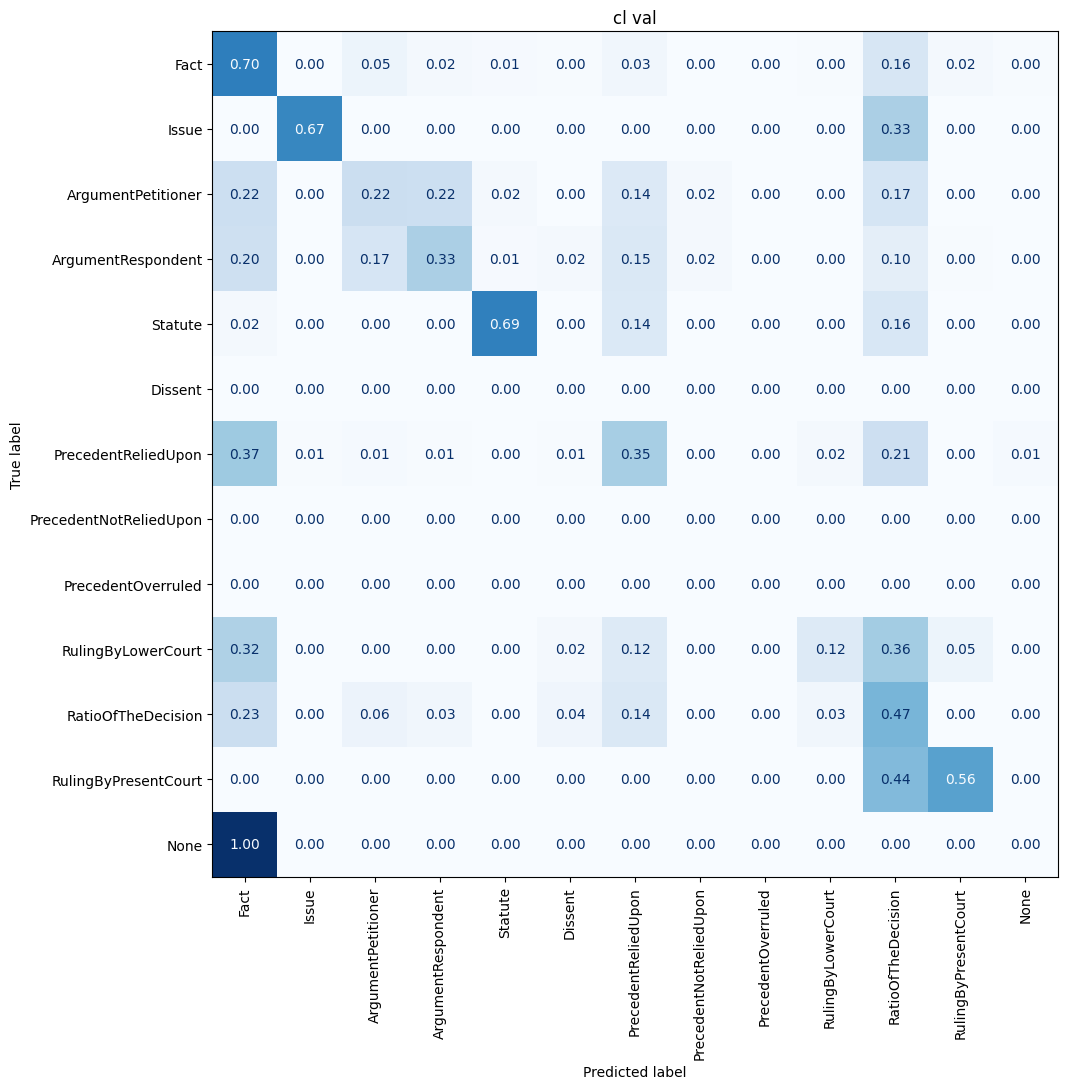

                     Class  True_Count  Predicted_Count     True_%  \
0                     Fact         249              435  17.836676   
6      PrecedentReliedUpon         142              195  10.171920   
10      RatioOfTheDecision         288              323  20.630372   
5                  Dissent           0               20   0.000000   
7   PrecedentNotReliedUpon           0               10   0.000000   
12                    None           2                3   0.143266   
1                    Issue           3                4   0.214900   
11    RulingByPresentCourt          18               18   1.289398   
8       PrecedentOverruled           0                0   0.000000   
4                  Statute          58               52   4.154728   
9       RulingByLowerCourt          56               22   4.011461   
3       ArgumentRespondent         236              168  16.905444   
2       ArgumentPetitioner         344              146  24.641834   

    Predicted_%  Pr

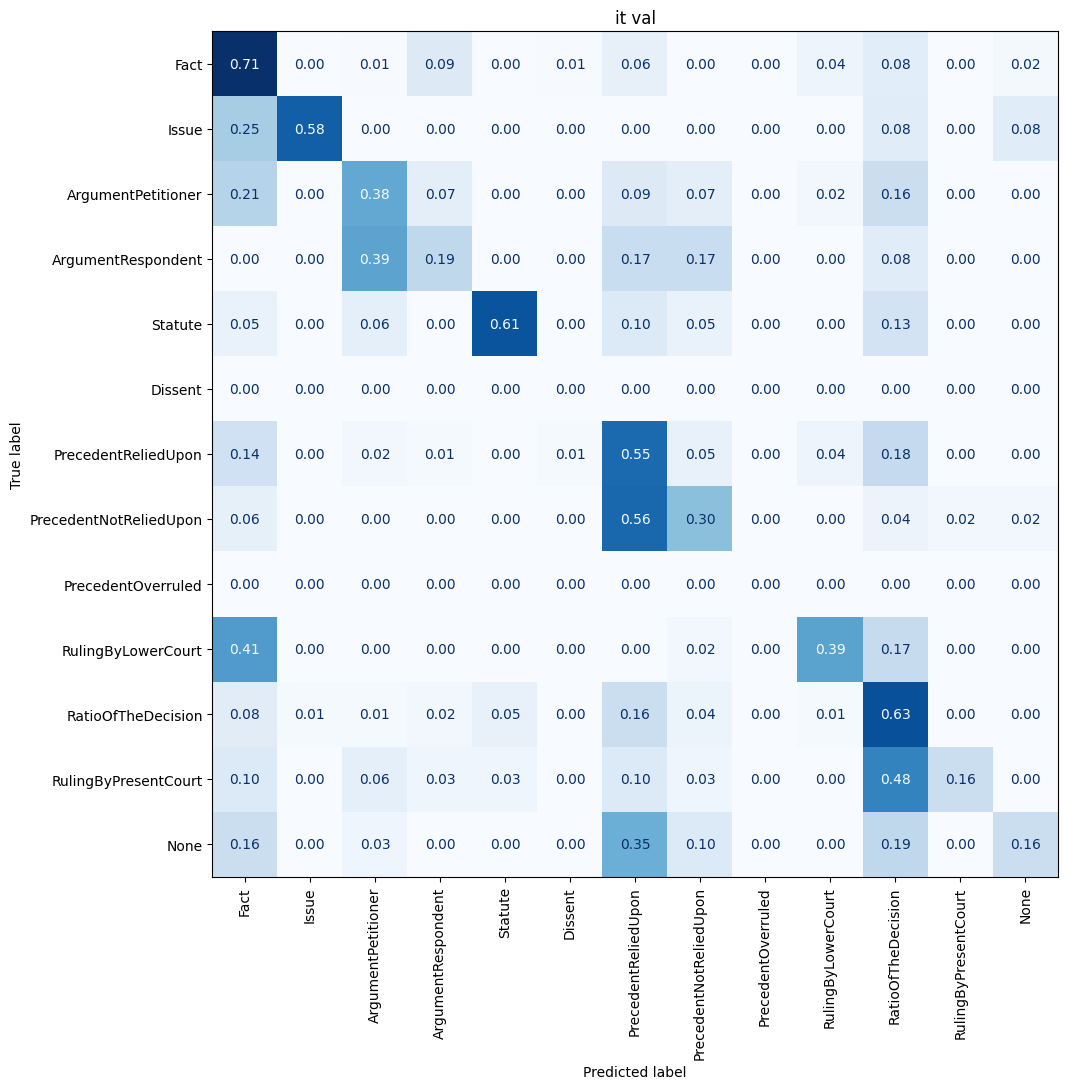

                     Class  True_Count  Predicted_Count     True_%  \
10      RatioOfTheDecision         115              159  15.415550   
6      PrecedentReliedUpon         112              150  15.013405   
0                     Fact         195              212  26.139410   
5                  Dissent           0                2   0.000000   
8       PrecedentOverruled           0                0   0.000000   
3       ArgumentRespondent          36               33   4.825737   
1                    Issue          12                8   1.608579   
7   PrecedentNotReliedUpon          50               44   6.702413   
2       ArgumentPetitioner          56               46   7.506702   
9       RulingByLowerCourt          46               31   6.166220   
4                  Statute          62               45   8.310992   
12                    None          31               10   4.155496   
11    RulingByPresentCourt          31                6   4.155496   

    Predicted_%  Pr

In [40]:
evaluate_all()

In [41]:

class RRTestDataset(Dataset):
    def __init__(self, ids, doc_ids, k=NUM_NEIGHBORS):
        assert len(ids) == len(doc_ids)

        self.ids = ids
        self.doc_ids = [str(x) for x in doc_ids]
        self.k = k

        n = len(ids)
        self.start = [0] * n
        self.end = [0] * n

        runs = (
            1 + sum(
                self.doc_ids[i] != self.doc_ids[i - 1]
                for i in range(1, n)
            )
            if n else 0
        )

        assert runs == len(set(self.doc_ids)), (
            "Document IDs must be contiguous."
        )

        i = 0
        while i < n:
            j = i

            while (
                j + 1 < n
                and self.doc_ids[j + 1] == self.doc_ids[i]
            ):
                j += 1

            for t in range(i, j + 1):
                self.start[t] = i
                self.end[t] = j

            i = j + 1

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        start, end = self.start[i], self.end[i]

        prev_sents = [
            self.ids[j]
            for j in range(
                i - 1,
                max(start, i - self.k) - 1,
                -1,
            )
        ]

        next_sents = [
            self.ids[j]
            for j in range(
                i + 1,
                min(end, i + self.k) + 1,
            )
        ]

        input_ids, target_mask = build_context(
            prev_sents,
            self.ids[i],
            next_sents,
        )

        rel_pos = (i - start) / max(end - start, 1)

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(target_mask, dtype=torch.bool),
            torch.tensor(rel_pos, dtype=torch.float32),
        )
def rr_test_collate_fn(batch):
    input_ids, target_masks, rel_positions = zip(*batch)

    lengths = torch.tensor([len(x) for x in input_ids])

    input_ids = torch.nn.utils.rnn.pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=PAD_ID,
    )

    target_masks = torch.nn.utils.rnn.pad_sequence(
        target_masks,
        batch_first=True,
        padding_value=False,
    )

    positions = torch.arange(input_ids.size(1))
    padding_mask = positions.unsqueeze(0) >= lengths.unsqueeze(1)

    return {
        "input_ids": input_ids,
        "padding_mask": padding_mask,
        "target_mask": target_masks,
        "rel_pos": torch.stack(rel_positions),
    }

def build_rr_test_data(data, tokenizer, max_seq_len=MAX_SEQ_LEN):
    test_ids = []
    test_doc_ids = []

    for doc_id, sentences in data.items():
        doc_id = str(doc_id)

        for sentence in sentences:
            token_ids = tokenizer.to_tokens([sentence])[0]
            token_ids = token_ids[:max_seq_len]

            test_ids.append(token_ids)
            test_doc_ids.append(doc_id)

    return test_ids, test_doc_ids


test_data ={**cl_test_data, **it_test_data}
test_ids, test_doc_ids = build_rr_test_data(
    test_data,
    converter,
    max_seq_len=MAX_SEQ_LEN,
)

test_dataset = RRTestDataset(
    ids=test_ids,
    doc_ids=test_doc_ids,
    k=NUM_NEIGHBORS,
)

In [42]:
print("Type:", type(test_data))
print("Number of entries:", len(test_data))

first_key = next(iter(test_data))
print("First key:", first_key)
print("First value type:", type(test_data[first_key]))
print("First value:", test_data[first_key][:3])

Type: <class 'dict'>
Number of entries: 10
First key: HC_Raghupati_Singhania__vs__Competition_Commission_ofDE201616051616063761COM513489
First value type: <class 'list'>
First value: ['Manmohan, J. 1 .', 'Present writ petition has been filed, challenging the notice dated 26th February, 2016 and respondent Number 1s order dated 18th February, 2016 whereby the respondent-CCI has directed the opposite parties in Reference Case Number 8/2013 to file their suggestions objections to the report of Director General (for short DG) and furnish their audited balance sheet, profit and loss account, turnover for the last three financial years.', 'The CCI has further directed individuals who have been identified in the DGs investigation report as key persons of the parties to appear before the CCI for oral hearing on the investigation report of DG.']


In [43]:
import json
from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import DataLoader


@torch.no_grad()
def generate_test_predictions(
    model,
    dataset,
    id2label,
    device,
    batch_size=16,
):
    model.eval()

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=rr_test_collate_fn,
        pin_memory=(device.type == "cuda"),
    )

    all_pred_ids = []

    use_amp = device.type == "cuda"
    amp_dtype =  torch.float16

    for batch in tqdm(loader, desc="Predicting"):
        batch = {
            key: value.to(device, non_blocking=True)
            for key, value in batch.items()
        }

        with torch.autocast(
            device_type=device.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            logits = model(
                input_ids=batch["input_ids"],
                padding_mask=batch["padding_mask"],
                target_mask=batch["target_mask"],
                rel_pos=batch["rel_pos"],
            )

        all_pred_ids.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    assert len(all_pred_ids) == len(dataset)

    predictions = {}

    for doc_id, pred_id in zip(dataset.doc_ids, all_pred_ids):
        predictions.setdefault(doc_id, []).append(id2label[pred_id])

    return predictions


PREDICTION_PATH = Path("/kaggle/working/prediction.json")

predictions = generate_test_predictions(
    model=model,
    dataset=test_dataset,
    id2label=id2label,
    device=device,
    batch_size=16,
)

with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, indent=2, ensure_ascii=False)

print("Saved:", PREDICTION_PATH)
print("Documents:", len(predictions))
print(
    "Total predictions:",
    sum(len(labels) for labels in predictions.values()),
)

Predicting:   0%|          | 0/138 [00:00<?, ?it/s]

Saved: /kaggle/working/prediction.json
Documents: 10
Total predictions: 2197


In [44]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase2/submission.zip


In [45]:
import os
import shutil
from IPython.display import display, FileLink

# Copy to Kaggle's working directory with a simple filename
download_path = "/kaggle/working/submission.zip"

shutil.copy2(SUBMISSION_ZIP, download_path)

print("Exists:", os.path.isfile(download_path))
print("Size:", os.path.getsize(download_path), "bytes")

display(FileLink("submission.zip"))

Exists: True
Size: 1914 bytes


/kaggle/working/submission.zip